## IMPORT GRAPH

OK: ogni paziente ha un solo Oncotree Code.
Righe merged annotate con Oncotree Code: 6358
Pazienti annotati: 886

Istologie / Oncotree Code presenti nel dataset:


,n_rows,n_patients,n_genes
Oncotree Code,,,
PAAD,5713,807,530
PANET,373,46,211
PAAC,123,14,101
UCP,62,8,36
PAASC,59,7,42
MCN,9,2,8
PANEC,19,2,17


Creato dataframe per MCN: 2 pazienti, 9 righe
Creato dataframe per PAAC: 14 pazienti, 123 righe
Creato dataframe per PAAD: 807 pazienti, 5713 righe
Creato dataframe per PAASC: 7 pazienti, 59 righe
Creato dataframe per PANEC: 2 pazienti, 19 righe
Creato dataframe per PANET: 46 pazienti, 373 righe
Creato dataframe per UCP: 8 pazienti, 62 righe

[MCN] Saltato: solo 2 pazienti.

[PAAC] Pazienti: 14
[PAAC] Geni: 101
[PAAC] Edges after filters: 0
[PAAC] No edges to display with current thresholds.

[PAAD] Pazienti: 807
[PAAD] Geni: 530
[PAAD] Edges after filters: 114
[PAAD] KRAS subgraph: 51 genes, 106 edges


C:\Users\ironl\AppData\Local\Temp\ipykernel_33384\718226912.py:360: UserWarning: 

The connectionstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(


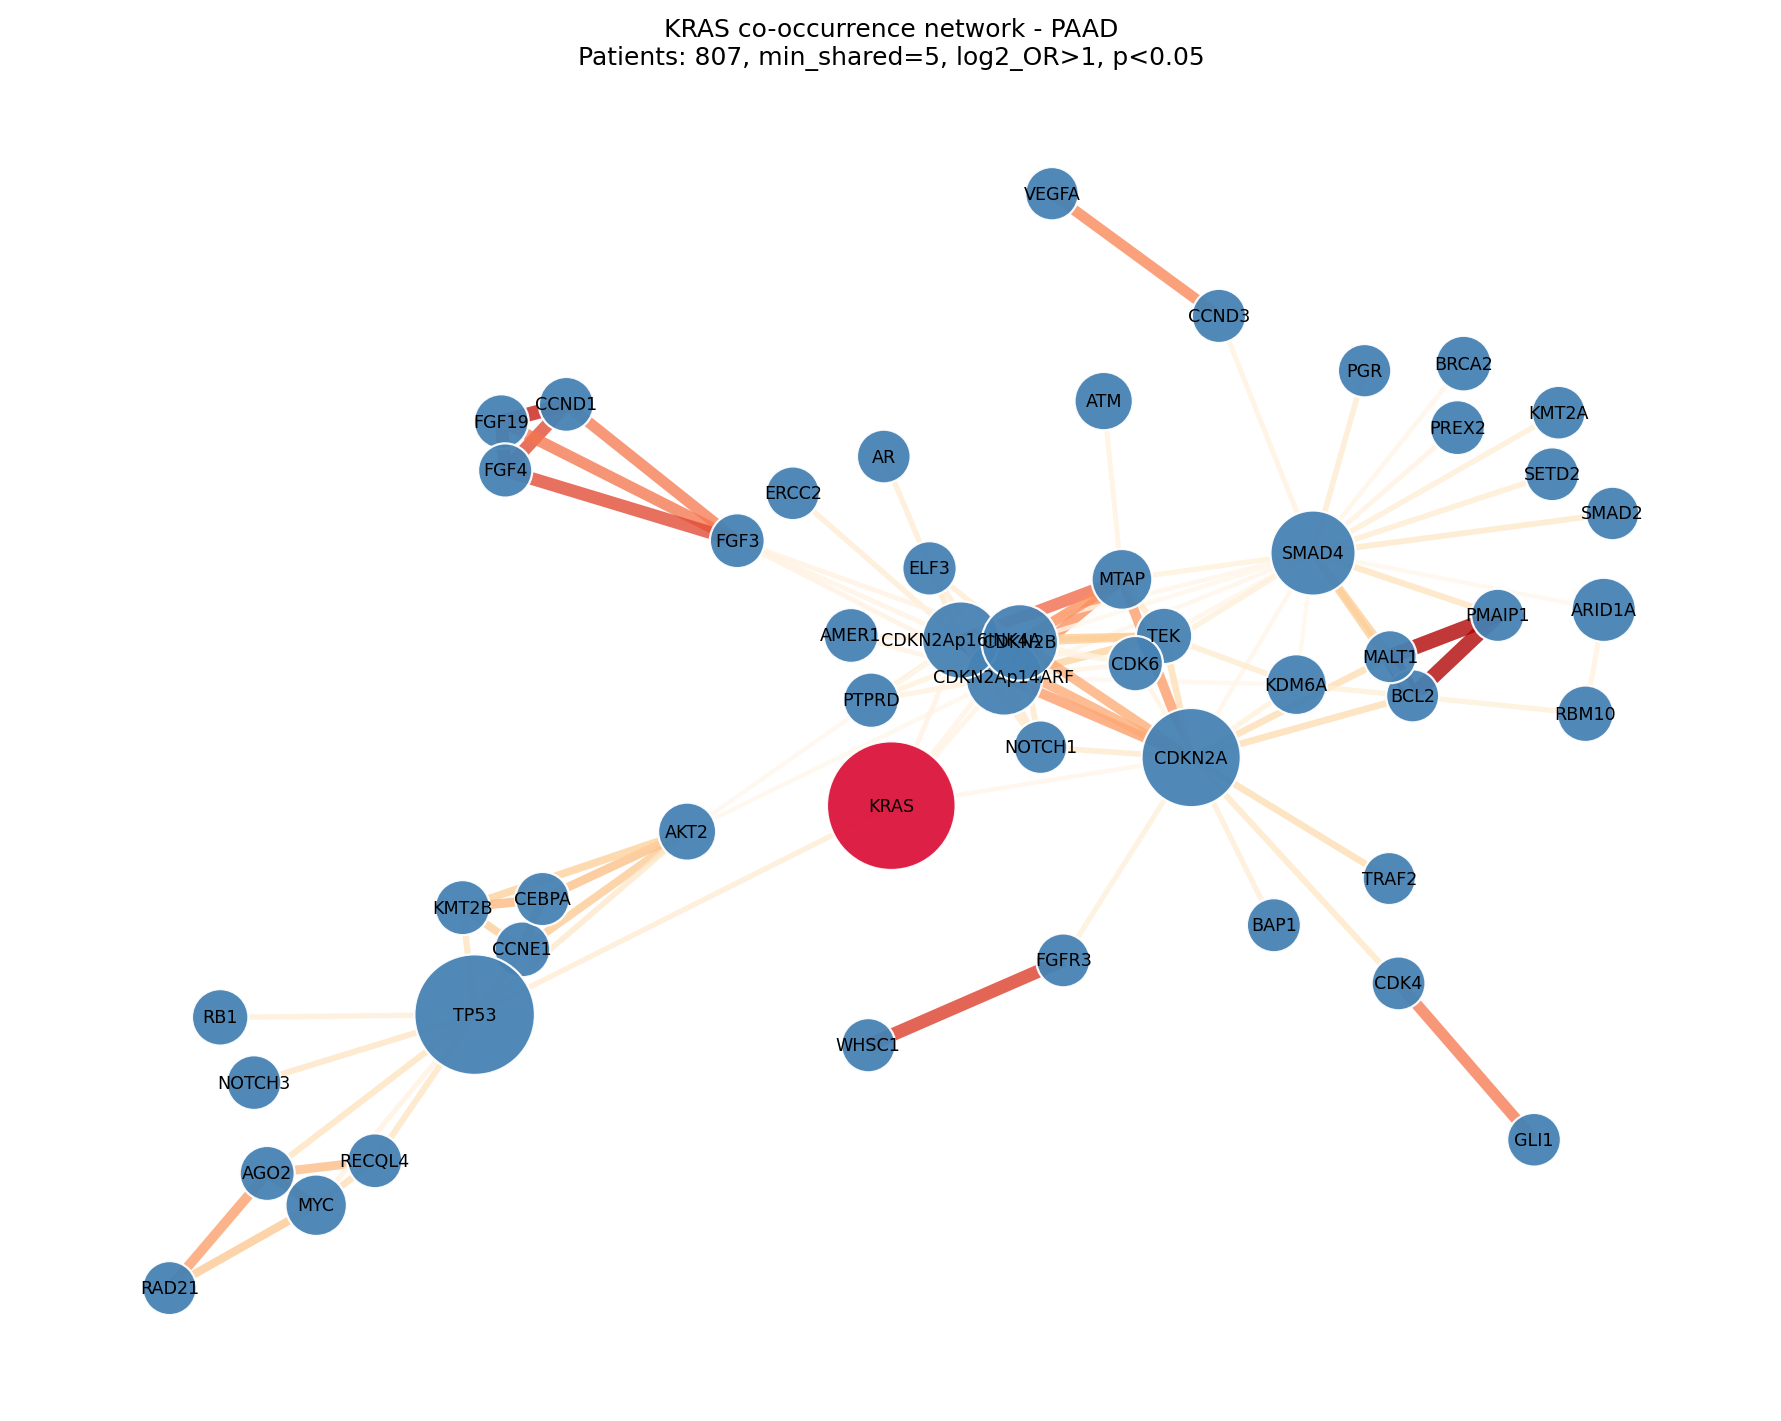

[PAAD] Figura salvata in: data_pancreas\networks_by_oncotree\kras_network_PAAD.png

[PAASC] Saltato: solo 7 pazienti.

[PANEC] Saltato: solo 2 pazienti.

[PANET] Pazienti: 46
[PANET] Geni: 211
[PANET] Edges after filters: 8
[PANET] KRAS non presente con questi threshold. Prova a rilassare i filtri.

[UCP] Saltato: solo 8 pazienti.


In [5]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import fisher_exact

# =========================
# PARAMETRI
# =========================

min_log2_or = 1
max_p_value = 0.05
min_shared = 5
max_hops_from_kras = None

min_patients_for_network = 10   # evita grafi inutili per istologie con pochissimi pazienti

data_dir = Path("data_pancreas")

file_path_merged = data_dir / "merged_mutations_cna_sv.csv"
file_path_filtered = data_dir / "filtered_data_PANCREAS.csv"

output_dir = data_dir / "networks_by_oncotree"
output_dir.mkdir(exist_ok=True)

# =========================
# CARICAMENTO DATASET
# =========================

df_merge = pd.read_csv(file_path_merged, low_memory=False)
df_filtered = pd.read_csv(file_path_filtered, low_memory=False)

# Controllo colonne indispensabili
required_merged_cols = {"Patient_ID", "Hugo_Symbol"}
required_filtered_cols = {"Patient_ID", "Oncotree Code"}

missing_merged = required_merged_cols - set(df_merge.columns)
missing_filtered = required_filtered_cols - set(df_filtered.columns)

if missing_merged:
    raise ValueError(f"Colonne mancanti in merged_mutations_cna_sv.csv: {missing_merged}")

if missing_filtered:
    raise ValueError(f"Colonne mancanti in filtered_data_PANCREAS.csv: {missing_filtered}")

# =========================
# MAPPA PAZIENTE -> ONCOTREE CODE
# =========================

patient_oncotree = (
    df_filtered[["Patient_ID", "Oncotree Code"]]
    .dropna()
    .drop_duplicates()
)

# Controllo se uno stesso paziente ha più Oncotree Code
multi_oncotree = (
    patient_oncotree
    .groupby("Patient_ID")["Oncotree Code"]
    .nunique()
)

patients_with_multiple_codes = multi_oncotree[multi_oncotree > 1]

if len(patients_with_multiple_codes) > 0:
    print("ATTENZIONE: alcuni pazienti hanno più Oncotree Code.")
    print(patients_with_multiple_codes.head())
else:
    print("OK: ogni paziente ha un solo Oncotree Code.")

# Aggiungo Oncotree Code al dataset merged
df_merge_oncotree = df_merge.merge(
    patient_oncotree,
    on="Patient_ID",
    how="left"
)

# Rimuovo righe senza Oncotree Code
df_merge_oncotree = df_merge_oncotree.dropna(subset=["Oncotree Code"]).copy()

print("Righe merged annotate con Oncotree Code:", len(df_merge_oncotree))
print("Pazienti annotati:", df_merge_oncotree["Patient_ID"].nunique())

# =========================
# IDENTIFICAZIONE ISTOLOGIE PRESENTI
# =========================

oncotree_summary = (
    df_merge_oncotree
    .groupby("Oncotree Code")
    .agg(
        n_rows=("Hugo_Symbol", "size"),
        n_patients=("Patient_ID", "nunique"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nIstologie / Oncotree Code presenti nel dataset:")
display(oncotree_summary)

# Salvo il riepilogo
oncotree_summary.to_csv(output_dir / "oncotree_summary.csv")

# =========================
# CREAZIONE DATAFRAME SEPARATI PER ONCOTREE CODE
# =========================

dfs_by_oncotree = {}

for code, df_code in df_merge_oncotree.groupby("Oncotree Code"):
    df_code = df_code.copy()
    dfs_by_oncotree[code] = df_code

    output_csv = output_dir / f"merged_mutations_cna_sv_{code}.csv"
    df_code.to_csv(output_csv, index=False)

    print(f"Creato dataframe per {code}: {df_code['Patient_ID'].nunique()} pazienti, {len(df_code)} righe")

# Esempi:
# dfs_by_oncotree["LUAD"] -> dataframe adenocarcinoma
# dfs_by_oncotree["LUSC"] -> dataframe squamous

# =========================
# FUNZIONE PER COSTRUIRE NETWORK
# =========================

def build_kras_network_for_oncotree(df_code, oncotree_code):
    """
    Costruisce la network di co-occorrenza dei geni per una specifica istologia,
    identificata da Oncotree Code.
    """

    n_patients = df_code["Patient_ID"].nunique()

    if n_patients < min_patients_for_network:
        print(f"\n[{oncotree_code}] Saltato: solo {n_patients} pazienti.")
        return None, None, None

    pairs = (
        df_code[["Patient_ID", "Hugo_Symbol"]]
        .dropna()
        .drop_duplicates()
    )

    if pairs.empty:
        print(f"\n[{oncotree_code}] Nessuna coppia Patient_ID/Hugo_Symbol disponibile.")
        return None, None, None

    patient_gene_m = (
        pd.crosstab(pairs["Patient_ID"], pairs["Hugo_Symbol"])
        .astype(bool)
        .astype(int)
    )

    N_m = patient_gene_m.shape[0]
    gene_counts_m = patient_gene_m.sum(axis=0)

    if patient_gene_m.shape[1] < 2:
        print(f"\n[{oncotree_code}] Meno di 2 geni disponibili, network non costruibile.")
        return None, None, None

    co_m = patient_gene_m.T @ patient_gene_m

    co_np = co_m.to_numpy(copy=True)
    np.fill_diagonal(co_np, 0)

    co_m = pd.DataFrame(
        co_np,
        index=co_m.index,
        columns=co_m.columns
    )

    edges_m = (
        co_m.where(np.triu(np.ones(co_m.shape), k=1).astype(bool))
        .stack()
        .rename("a_both")
        .rename_axis(index=["Gene1", "Gene2"])
        .reset_index()
    )

    edges_m = edges_m.dropna(subset=["a_both"]).copy()
    edges_m["a_both"] = edges_m["a_both"].astype(int)

    rows = []

    for row in edges_m.itertuples(index=False):
        g1, g2, a = row.Gene1, row.Gene2, int(row.a_both)

        b = int(gene_counts_m[g1] - a)
        c = int(gene_counts_m[g2] - a)
        d = int(N_m - a - b - c)

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        log2_or = np.log2(
            ((a + 0.5) * (d + 0.5)) /
            ((b + 0.5) * (c + 0.5))
        )

        rows.append([
            g1,
            g2,
            a,
            b,
            c,
            d,
            odds_ratio,
            log2_or,
            p_value
        ])

    results_m = pd.DataFrame(
        rows,
        columns=[
            "Gene1",
            "Gene2",
            "a_both",
            "b_g1_only",
            "c_g2_only",
            "d_neither",
            "odds_ratio",
            "log2_OR",
            "p_value"
        ]
    )

    edges_plot = results_m[
        (results_m["log2_OR"] > min_log2_or)
        & (results_m["p_value"] < max_p_value)
        & (results_m["a_both"] >= min_shared)
        ].sort_values(
        ["p_value", "log2_OR"],
        ascending=[True, False]
    ).copy()

    print(f"\n[{oncotree_code}] Pazienti: {N_m}")
    print(f"[{oncotree_code}] Geni: {patient_gene_m.shape[1]}")
    print(f"[{oncotree_code}] Edges after filters: {len(edges_plot)}")

    # Salvo risultati statistici
    results_m.to_csv(
        output_dir / f"cooccurrence_results_{oncotree_code}.csv",
        index=False
    )

    edges_plot.to_csv(
        output_dir / f"cooccurrence_edges_filtered_{oncotree_code}.csv",
        index=False
    )

    G_plot = nx.Graph()

    for _, row in edges_plot.iterrows():
        G_plot.add_edge(
            row["Gene1"],
            row["Gene2"],
            log2_or=float(row["log2_OR"]),
            p_value=float(row["p_value"]),
            shared=int(row["a_both"]),
        )

    if G_plot.number_of_nodes() == 0 or G_plot.number_of_edges() == 0:
        print(f"[{oncotree_code}] No edges to display with current thresholds.")
        return results_m, edges_plot, G_plot

    kras_nodes = [n for n in G_plot.nodes() if str(n).upper() == "KRAS"]

    if not kras_nodes:
        print(f"[{oncotree_code}] KRAS non presente con questi threshold. Prova a rilassare i filtri.")
        return results_m, edges_plot, G_plot

    kras_node = kras_nodes[0]

    distances = nx.single_source_shortest_path_length(G_plot, kras_node)

    if max_hops_from_kras is None:
        keep_nodes = set(distances.keys())
    else:
        keep_nodes = {
            n for n, d in distances.items()
            if d <= max_hops_from_kras
        }

    G_kras = G_plot.subgraph(keep_nodes).copy()

    print(
        f"[{oncotree_code}] KRAS subgraph: "
        f"{G_kras.number_of_nodes()} genes, "
        f"{G_kras.number_of_edges()} edges"
    )

    if G_kras.number_of_edges() == 0:
        return results_m, edges_plot, G_kras

    local_dist = nx.single_source_shortest_path_length(G_kras, kras_node)

    shells = [[kras_node]] + [
        [n for n in G_kras.nodes() if local_dist[n] == d]
        for d in range(1, max(local_dist.values()) + 1)
    ]

    pos0 = nx.shell_layout(G_kras, nlist=shells)
    pos0[kras_node] = np.array([0.0, 0.0])

    pos = nx.spring_layout(
        G_kras,
        seed=42,
        k=0.9,
        pos=pos0,
        fixed=[kras_node],
        center=(0, 0),
        iterations=200
    )

    support = gene_counts_m.to_dict()

    support_vals = [
        float(support.get(n, 1))
        for n in G_kras.nodes()
    ]

    s_min = min(support_vals) if support_vals else 1.0
    s_max = max(support_vals) if support_vals else 1.0

    if s_max == s_min:
        node_sizes = [1000 for _ in G_kras.nodes()]
    else:
        node_sizes = [
            450 + 2200 * (
                    (float(support.get(n, s_min)) - s_min) /
                    (s_max - s_min)
            )
            for n in G_kras.nodes()
        ]

    node_colors = [
        "crimson" if str(n).upper() == "KRAS" else "steelblue"
        for n in G_kras.nodes()
    ]

    edge_vals = [
        G_kras[u][v].get("log2_or", 1.0)
        for u, v in G_kras.edges()
    ]

    max_edge = max(edge_vals) if edge_vals else 1.0

    edge_widths = [
        1.4 + 5.2 * (w / max_edge)
        for w in edge_vals
    ]

    plt.figure(figsize=(10, 8), dpi=180)

    nx.draw_networkx_edges(
        G_kras,
        pos,
        width=edge_widths,
        alpha=0.78,
        edge_color=edge_vals,
        edge_cmap=plt.cm.OrRd,
        edge_vmin=min(edge_vals) if edge_vals else 0.0,
        edge_vmax=max(edge_vals) if edge_vals else 1.0,
        connectionstyle="arc3,rad=0.06",
    )

    nx.draw_networkx_nodes(
        G_kras,
        pos,
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.95,
        linewidths=0.9,
        edgecolors="white",
    )

    nx.draw_networkx_labels(
        G_kras,
        pos,
        labels={n: n for n in G_kras.nodes()},
        font_size=7
    )

    plt.title(
        f"KRAS co-occurrence network - {oncotree_code}\n"
        f"Patients: {N_m}, min_shared={min_shared}, "
        f"log2_OR>{min_log2_or}, p<{max_p_value}",
        fontsize=10
    )

    plt.axis("off")
    plt.tight_layout()

    fig_path = output_dir / f"kras_network_{oncotree_code}.png"
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")

    plt.show()

    print(f"[{oncotree_code}] Figura salvata in: {fig_path}")

    return results_m, edges_plot, G_kras


# =========================
# COSTRUZIONE NETWORK PER OGNI ONCOTREE CODE
# =========================

results_by_oncotree = {}
edges_by_oncotree = {}
graphs_by_oncotree = {}

for oncotree_code, df_code in dfs_by_oncotree.items():
    results_m, edges_plot, G_kras = build_kras_network_for_oncotree(
        df_code=df_code,
        oncotree_code=oncotree_code
    )

    results_by_oncotree[oncotree_code] = results_m
    edges_by_oncotree[oncotree_code] = edges_plot
    graphs_by_oncotree[oncotree_code] = G_kras

***
## HUB MUTATION centrality metrics

In [6]:
# =========================
# HUB METRICS PER ONCOTREE CODE / ISTOLOGIA
# =========================

hub_output_dir = output_dir / "hub_metrics_by_oncotree"
hub_output_dir.mkdir(exist_ok=True)

# Se True, calcola hub metrics solo sui grafi che contengono KRAS.
# Consigliato nel tuo caso, perché stai studiando il KRAS subgraph.
require_kras = True

top_n = 20

hub_tables_by_oncotree = {}

def compute_hub_metrics_for_graph(G_hub, graph_name, require_kras=True):
    """
    Calcola le metriche hub per un grafo NetworkX.
    Se require_kras=True, salta i grafi che non contengono KRAS.
    """

    if G_hub is None:
        print(f"[{graph_name}] Saltato: grafo None.")
        return None

    if G_hub.number_of_nodes() == 0 or G_hub.number_of_edges() == 0:
        print(f"[{graph_name}] Saltato: grafo vuoto o senza edges.")
        return None

    has_kras = any(str(n).upper() == "KRAS" for n in G_hub.nodes())

    if require_kras and not has_kras:
        print(f"[{graph_name}] Saltato: KRAS non presente nel grafo.")
        return None

    # =========================
    # Decide whether to include eigenvector centrality
    # =========================

    use_eigenvector = True

    if nx.density(G_hub) < 0.1:
        use_eigenvector = False
        print(f"[{graph_name}] Eigenvector centrality NON inclusa: grafo molto sparso.")
    elif not nx.is_connected(G_hub):
        use_eigenvector = False
        print(f"[{graph_name}] Eigenvector centrality NON inclusa: grafo disconnesso.")
    else:
        print(f"[{graph_name}] Eigenvector centrality inclusa.")

    # =========================
    # Basic centrality metrics
    # =========================

    degree = dict(G_hub.degree())

    strength = {
        n: sum(G_hub[n][nbr].get("log2_or", 1.0) for nbr in G_hub.neighbors(n))
        for n in G_hub.nodes()
    }

    betweenness = nx.betweenness_centrality(
        G_hub,
        normalized=True,
        weight=None
    )

    closeness = nx.closeness_centrality(G_hub)

    # =========================
    # Eigenvector centrality
    # =========================

    if use_eigenvector:
        try:
            eigenvector = nx.eigenvector_centrality_numpy(G_hub)
        except Exception as e:
            eigenvector = {n: np.nan for n in G_hub.nodes()}
            use_eigenvector = False
            print(f"[{graph_name}] Eigenvector centrality fallita e NON inclusa.")
            print("Errore:", e)
    else:
        eigenvector = {n: np.nan for n in G_hub.nodes()}

    # =========================
    # Create hub table
    # =========================

    hub_table = pd.DataFrame({
        "Oncotree Code": graph_name,
        "Gene": list(G_hub.nodes()),
        "Degree": [degree[n] for n in G_hub.nodes()],
        "Node Strength": [strength[n] for n in G_hub.nodes()],
        "Betweenness": [betweenness[n] for n in G_hub.nodes()],
        "Closeness": [closeness[n] for n in G_hub.nodes()],
        "Eigenvector": [eigenvector[n] for n in G_hub.nodes()],
        "Contains_KRAS": has_kras,
        "Graph_nodes": G_hub.number_of_nodes(),
        "Graph_edges": G_hub.number_of_edges(),
        "Graph_density": nx.density(G_hub),
    })

    # =========================
    # Additional useful metrics
    # =========================

    n_nodes = G_hub.number_of_nodes()
    denom = (n_nodes - 1) if n_nodes > 1 else 1

    hub_table["Degree_norm"] = hub_table["Degree"] / denom

    hub_table["Mean_log2_or_per_edge"] = (
            hub_table["Node Strength"] / hub_table["Degree"].replace(0, pd.NA)
    )

    # =========================
    # Composite HubScore
    # =========================

    if use_eigenvector:
        hub_table["HubScore"] = (
                hub_table["Degree"].rank(pct=True) * 0.20
                + hub_table["Node Strength"].rank(pct=True) * 0.20
                + hub_table["Betweenness"].rank(pct=True) * 0.20
                + hub_table["Closeness"].rank(pct=True) * 0.20
                + hub_table["Eigenvector"].fillna(0).rank(pct=True) * 0.20
        )

        score_description = (
            "HubScore = 20% Degree + 20% Node Strength + 20% Betweenness "
            "+ 20% Closeness + 20% Eigenvector"
        )

    else:
        hub_table["HubScore"] = (
                hub_table["Degree"].rank(pct=True) * 0.25
                + hub_table["Node Strength"].rank(pct=True) * 0.25
                + hub_table["Betweenness"].rank(pct=True) * 0.25
                + hub_table["Closeness"].rank(pct=True) * 0.25
        )

        score_description = (
            "HubScore = 25% Degree + 25% Node Strength + 25% Betweenness "
            "+ 25% Closeness"
        )

    hub_table = hub_table.sort_values("HubScore", ascending=False).reset_index(drop=True)

    # =========================
    # Display results
    # =========================

    print("\n" + "=" * 70)
    print(f"Graph analyzed: {graph_name}")
    print(f"Nodes: {G_hub.number_of_nodes()} | Edges: {G_hub.number_of_edges()}")
    print(f"Density: {nx.density(G_hub):.4f}")
    print(f"Contains KRAS: {has_kras}")
    print(score_description)
    print(f"\nTop {top_n} hub genes:")

    display_cols = [
        "Oncotree Code",
        "Gene",
        "Degree",
        "Degree_norm",
        "Node Strength",
        "Mean_log2_or_per_edge",
        "Betweenness",
        "Closeness",
    ]

    if use_eigenvector:
        display_cols.append("Eigenvector")

    display_cols.append("HubScore")

    display(hub_table[display_cols].head(top_n))

    # Salvataggio CSV per singolo Oncotree Code
    output_file = hub_output_dir / f"hub_metrics_{graph_name}.csv"
    hub_table.to_csv(output_file, index=False)

    print(f"[{graph_name}] Hub metrics salvate in: {output_file}")

    return hub_table


# =========================
# CALCOLO HUB METRICS PER OGNI GRAFO
# =========================

for oncotree_code, G in graphs_by_oncotree.items():
    hub_table = compute_hub_metrics_for_graph(
        G_hub=G,
        graph_name=oncotree_code,
        require_kras=require_kras
    )

    if hub_table is not None:
        hub_tables_by_oncotree[oncotree_code] = hub_table


# =========================
# TABELLA FINALE COMBINATA
# =========================

if len(hub_tables_by_oncotree) > 0:
    all_hub_tables = pd.concat(
        hub_tables_by_oncotree.values(),
        ignore_index=True
    )

    all_hub_tables = all_hub_tables.sort_values(
        ["Oncotree Code", "HubScore"],
        ascending=[True, False]
    ).reset_index(drop=True)

    combined_file = hub_output_dir / "hub_metrics_all_oncotree.csv"
    all_hub_tables.to_csv(combined_file, index=False)

    print("\nTabella combinata creata:")
    print(combined_file)

    display(all_hub_tables.head(30))

else:
    all_hub_tables = pd.DataFrame()
    print("Nessuna hub table creata.")

[MCN] Saltato: grafo None.
[PAAC] Saltato: grafo vuoto o senza edges.
[PAAD] Eigenvector centrality NON inclusa: grafo molto sparso.

Graph analyzed: PAAD
Nodes: 51 | Edges: 106
Density: 0.0831
Contains KRAS: True
HubScore = 25% Degree + 25% Node Strength + 25% Betweenness + 25% Closeness

Top 20 hub genes:


,Oncotree Code,Gene,Degree,Degree_norm,Node Strength,Mean_log2_or_per_edge,Betweenness,Closeness,HubScore
0,PAAD,CDKN2Ap16INK4A,16,0.32,60.480508,3.780032,0.237279,0.526316,0.980392
1,PAAD,CDKN2A,16,0.32,55.546751,3.471672,0.290605,0.510204,0.968137
2,PAAD,SMAD4,19,0.38,37.555167,1.976588,0.376068,0.485437,0.960784
3,PAAD,CDKN2Ap14ARF,15,0.30,56.713809,3.780921,0.187986,0.526316,0.958333
4,PAAD,CDKN2B,13,0.26,52.012115,4.000932,0.083286,0.495050,0.911765
5,PAAD,MTAP,7,0.14,37.149839,5.307120,0.040000,0.427350,0.857843
6,PAAD,FGF3,6,0.12,31.409757,5.234960,0.115102,0.373134,0.821078
7,PAAD,AKT2,6,0.12,19.769146,3.294858,0.154136,0.413223,0.803922
8,PAAD,TP53,9,0.18,23.423470,2.602608,0.230259,0.347222,0.803922
9,PAAD,TEK,7,0.14,23.278232,3.325462,0.002204,0.431034,0.776961


[PAAD] Hub metrics salvate in: data_pancreas\networks_by_oncotree\hub_metrics_by_oncotree\hub_metrics_PAAD.csv
[PAASC] Saltato: grafo None.
[PANEC] Saltato: grafo None.
[PANET] Saltato: KRAS non presente nel grafo.
[UCP] Saltato: grafo None.

Tabella combinata creata:
data_pancreas\networks_by_oncotree\hub_metrics_by_oncotree\hub_metrics_all_oncotree.csv


,Oncotree Code,Gene,Degree,Node Strength,Betweenness,Closeness,Eigenvector,Contains_KRAS,Graph_nodes,Graph_edges,Graph_density,Degree_norm,Mean_log2_or_per_edge,HubScore
0,PAAD,CDKN2Ap16INK4A,16,60.480508,0.237279,0.526316,NaN,True,51,106,0.083137,0.32,3.780032,0.980392
1,PAAD,CDKN2A,16,55.546751,0.290605,0.510204,NaN,True,51,106,0.083137,0.32,3.471672,0.968137
2,PAAD,SMAD4,19,37.555167,0.376068,0.485437,NaN,True,51,106,0.083137,0.38,1.976588,0.960784
3,PAAD,CDKN2Ap14ARF,15,56.713809,0.187986,0.526316,NaN,True,51,106,0.083137,0.30,3.780921,0.958333
4,PAAD,CDKN2B,13,52.012115,0.083286,0.495050,NaN,True,51,106,0.083137,0.26,4.000932,0.911765
5,PAAD,MTAP,7,37.149839,0.040000,0.427350,NaN,True,51,106,0.083137,0.14,5.307120,0.857843
6,PAAD,FGF3,6,31.409757,0.115102,0.373134,NaN,True,51,106,0.083137,0.12,5.234960,0.821078
7,PAAD,AKT2,6,19.769146,0.154136,0.413223,NaN,True,51,106,0.083137,0.12,3.294858,0.803922
8,PAAD,TP53,9,23.423470,0.230259,0.347222,NaN,True,51,106,0.083137,0.18,2.602608,0.803922
9,PAAD,TEK,7,23.278232,0.002204,0.431034,NaN,True,51,106,0.083137,0.14,3.325462,0.776961


### TOP 10 % MUTATIONAL HUB IN PANCREAS ALL GRAPH

In [7]:
# score_col = "HubScore_1over5" if "HubScore_1over5" in hub_table.columns else ("HubScore_equal" if "HubScore_equal" in hub_table.columns else "HubScore")
# if score_col not in hub_table.columns:
#     raise ValueError("Nessuna colonna HubScore trovata. Esegui prima la cella hub metrics / ranking.")
# table = hub_table[["Gene", score_col]].copy().rename(columns={score_col: "HubScore"})
#
# threshold = table["HubScore"].quantile(0.90)
# top_genes = (
#     table.loc[table["HubScore"] >= threshold]
#     .sort_values("HubScore", ascending=False)["Gene"]
#     .astype(str)
#     .tolist()
# )
#
# print(" ".join(top_genes))

***
## CLUSTERING

### 1. Leiden Stability con ARI e modularity e best SEED

[MCN] Saltato: grafo None.
[PAAC] Saltato: grafo vuoto o senza edges.

Graph analyzed: PAAD
Nodes: 51 | Edges: 106
Density: 0.0831
Contains KRAS: True

=== Leiden Stability - ARI ===
Mean ARI: 0.9986
Std ARI: 0.0098
Min ARI: 0.9302
Max ARI: 1.0000

=== Leiden Modularity ===
Mean modularity: 0.6589
Std modularity: 0.0001
Min modularity: 0.6584
Max modularity: 0.6589

=== Number of clusters frequency ===


,Oncotree Code,Algorithm,Num_clusters,Frequency,Percentage
0,PAAD,Leiden,8,1,1.0
1,PAAD,Leiden,9,99,99.0



Most frequent Leiden partition: 9 clusters (99/100 runs, 99.0%)
Best Leiden partition by modularity: 9 clusters, seed=0, modularity=0.6589

Best partition preview:


,Oncotree Code,Gene,Leiden_cluster,Best_seed,Best_modularity
0,PAAD,CDKN2Ap14ARF,0,0,0.658918
1,PAAD,CDKN2Ap16INK4A,0,0,0.658918
2,PAAD,CDKN2B,0,0,0.658918
3,PAAD,CDKN2A,0,0,0.658918
4,PAAD,MTAP,0,0,0.658918
5,PAAD,CCND1,3,0,0.658918
6,PAAD,FGF19,3,0,0.658918
7,PAAD,FGF4,3,0,0.658918
8,PAAD,FGF3,3,0,0.658918
9,PAAD,FGFR3,5,0,0.658918


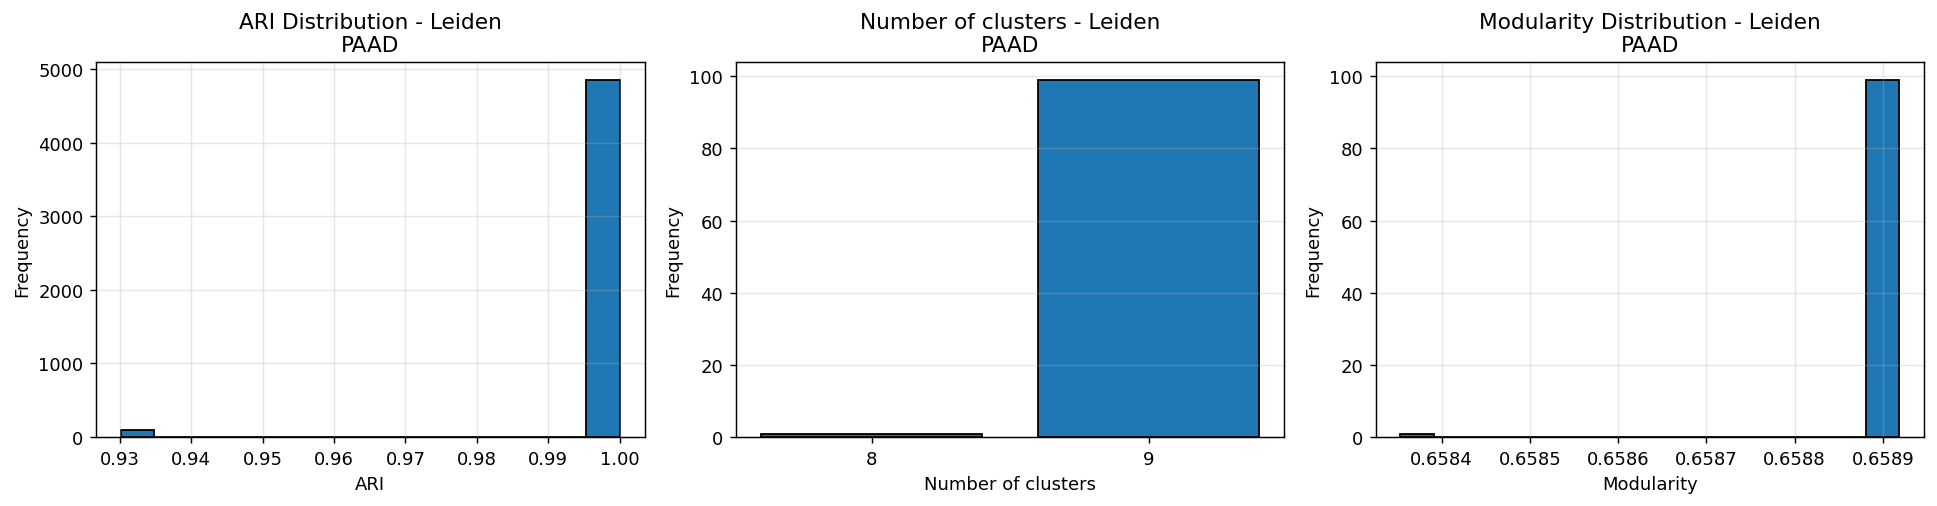

[PAAD] Plot salvato in: data_pancreas\networks_by_oncotree\leiden_by_oncotree\leiden_stability_plots_PAAD.png
[PAASC] Saltato: grafo None.
[PANEC] Saltato: grafo None.
[PANET] Saltato: KRAS non presente nel grafo.
[UCP] Saltato: grafo None.

Leiden analysis completed for these Oncotree Codes:
['PAAD']

Combined Leiden summary:


,Oncotree Code,Algorithm,Nodes,Edges,Density,Contains_KRAS,Resolution,Runs,Mean_ARI,Std_ARI,...,Mean_modularity,Std_modularity,Min_modularity,Max_modularity,Best_seed,Best_modularity,Best_num_clusters,Most_frequent_num_clusters,Most_frequent_cluster_count_frequency,Most_frequent_cluster_count_percentage
0,PAAD,Leiden,51,106,0.083137,True,1.0,100,0.998604,0.009774,...,0.658913,0.000056,0.658353,0.658918,0,0.658918,9,9,99,99.0



Combined Leiden cluster frequency:


,Oncotree Code,Algorithm,Num_clusters,Frequency,Percentage
0,PAAD,Leiden,8,1,1.0
1,PAAD,Leiden,9,99,99.0



Combined best partitions preview:


,Oncotree Code,Gene,Leiden_cluster,Best_seed,Best_modularity
0,PAAD,CDKN2Ap14ARF,0,0,0.658918
1,PAAD,CDKN2Ap16INK4A,0,0,0.658918
2,PAAD,CDKN2B,0,0,0.658918
3,PAAD,CDKN2A,0,0,0.658918
4,PAAD,MTAP,0,0,0.658918
5,PAAD,CCND1,3,0,0.658918
6,PAAD,FGF19,3,0,0.658918
7,PAAD,FGF4,3,0,0.658918
8,PAAD,FGF3,3,0,0.658918
9,PAAD,FGFR3,5,0,0.658918


In [8]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from collections import Counter
from pathlib import Path

try:
    import igraph as ig
    import leidenalg
except ImportError as e:
    raise ImportError(
        "Per usare Leiden devi installare 'igraph' e 'leidenalg'. "
        "Esempio: pip install python-igraph leidenalg"
    ) from e


# ============================================================
# PARAMETRI LEIDEN
# ============================================================

n_runs = 100
seeds = list(range(n_runs))
resolution_parameter = 1.0

# Se True, fa Leiden solo sui grafi che contengono KRAS.
# Nel tuo caso è coerente, perché stai usando G_kras / KRAS subgraph.
require_kras = True

leiden_output_dir = output_dir / "leiden_by_oncotree"
leiden_output_dir.mkdir(exist_ok=True)


# ============================================================
# FUNZIONI DI SUPPORTO
# ============================================================

def cluster_frequency_df(num_clusters, algorithm_name, oncotree_code, n_runs):
    freq = Counter(num_clusters)

    df = (
        pd.DataFrame({
            "Oncotree Code": oncotree_code,
            "Algorithm": algorithm_name,
            "Num_clusters": list(freq.keys()),
            "Frequency": list(freq.values())
        })
        .sort_values("Num_clusters")
        .reset_index(drop=True)
    )

    df["Percentage"] = (df["Frequency"] / n_runs * 100).round(2)

    return df


def compute_pairwise_ari(partitions):
    ari_scores = []

    for i in range(len(partitions)):
        for j in range(i + 1, len(partitions)):
            ari = adjusted_rand_score(partitions[i], partitions[j])
            ari_scores.append(ari)

    return np.array(ari_scores)


def run_leiden_stability_for_graph(G_test, oncotree_code):
    """
    Esegue Leiden n volte sul grafo di una specifica istologia / Oncotree Code.
    Calcola:
    - stabilità tramite ARI
    - modularity
    - frequenza del numero di cluster
    - partizione migliore
    """

    if G_test is None:
        print(f"[{oncotree_code}] Saltato: grafo None.")
        return None

    if G_test.number_of_nodes() == 0 or G_test.number_of_edges() == 0:
        print(f"[{oncotree_code}] Saltato: grafo vuoto o senza edges.")
        return None

    has_kras = any(str(n).upper() == "KRAS" for n in G_test.nodes())

    if require_kras and not has_kras:
        print(f"[{oncotree_code}] Saltato: KRAS non presente nel grafo.")
        return None

    print("\n" + "=" * 80)
    print(f"Graph analyzed: {oncotree_code}")
    print(f"Nodes: {G_test.number_of_nodes()} | Edges: {G_test.number_of_edges()}")
    print(f"Density: {nx.density(G_test):.4f}")
    print(f"Contains KRAS: {has_kras}")

    node_list = list(G_test.nodes())

    # ============================================================
    # CONVERSIONE NETWORKX -> IGRAPH
    # ============================================================

    node_to_idx = {
        node: i
        for i, node in enumerate(node_list)
    }

    edges = []
    weights = []

    for u, v, data in G_test.edges(data=True):
        edges.append((node_to_idx[u], node_to_idx[v]))
        weights.append(float(data.get("log2_or", 1.0)))

    g_ig = ig.Graph(
        n=len(node_list),
        edges=edges,
        directed=False
    )

    g_ig.vs["name"] = node_list
    g_ig.es["weight"] = weights

    # ============================================================
    # LEIDEN MULTIPLE RUNS
    # ============================================================

    partitions_leiden = []
    num_clusters_leiden = []
    modularity_leiden = []
    membership_tables = []

    for seed in seeds:
        partition = leidenalg.find_partition(
            g_ig,
            leidenalg.RBConfigurationVertexPartition,
            weights=g_ig.es["weight"],
            resolution_parameter=resolution_parameter,
            seed=seed
        )

        labels = list(partition.membership)

        modularity_value = g_ig.modularity(
            labels,
            weights=g_ig.es["weight"]
        )

        partitions_leiden.append(labels)
        num_clusters_leiden.append(len(set(labels)))
        modularity_leiden.append(modularity_value)

        tmp_membership = pd.DataFrame({
            "Oncotree Code": oncotree_code,
            "Seed": seed,
            "Gene": node_list,
            "Cluster": labels
        })

        membership_tables.append(tmp_membership)

    # ============================================================
    # ARI LEIDEN
    # ============================================================

    ari_scores_leiden = compute_pairwise_ari(partitions_leiden)

    # ============================================================
    # FREQUENCY TABLE
    # ============================================================

    cluster_freq_leiden_df = cluster_frequency_df(
        num_clusters=num_clusters_leiden,
        algorithm_name="Leiden",
        oncotree_code=oncotree_code,
        n_runs=n_runs
    )

    # ============================================================
    # BEST PARTITION
    # ============================================================

    best_run_idx = int(np.argmax(modularity_leiden))
    best_seed = seeds[best_run_idx]
    best_modularity = modularity_leiden[best_run_idx]
    best_labels = partitions_leiden[best_run_idx]

    best_partition_df = pd.DataFrame({
        "Oncotree Code": oncotree_code,
        "Gene": node_list,
        "Leiden_cluster": best_labels,
        "Best_seed": best_seed,
        "Best_modularity": best_modularity
    })

    most_common_leiden = cluster_freq_leiden_df.sort_values(
        ["Frequency", "Num_clusters"],
        ascending=[False, True]
    ).iloc[0]

    # ============================================================
    # SUMMARY
    # ============================================================

    summary_row = {
        "Oncotree Code": oncotree_code,
        "Algorithm": "Leiden",
        "Nodes": G_test.number_of_nodes(),
        "Edges": G_test.number_of_edges(),
        "Density": nx.density(G_test),
        "Contains_KRAS": has_kras,
        "Resolution": resolution_parameter,
        "Runs": n_runs,
        "Mean_ARI": ari_scores_leiden.mean() if len(ari_scores_leiden) > 0 else np.nan,
        "Std_ARI": ari_scores_leiden.std() if len(ari_scores_leiden) > 0 else np.nan,
        "Min_ARI": ari_scores_leiden.min() if len(ari_scores_leiden) > 0 else np.nan,
        "Max_ARI": ari_scores_leiden.max() if len(ari_scores_leiden) > 0 else np.nan,
        "Mean_modularity": np.mean(modularity_leiden),
        "Std_modularity": np.std(modularity_leiden),
        "Min_modularity": np.min(modularity_leiden),
        "Max_modularity": np.max(modularity_leiden),
        "Best_seed": best_seed,
        "Best_modularity": best_modularity,
        "Best_num_clusters": len(set(best_labels)),
        "Most_frequent_num_clusters": int(most_common_leiden["Num_clusters"]),
        "Most_frequent_cluster_count_frequency": int(most_common_leiden["Frequency"]),
        "Most_frequent_cluster_count_percentage": float(most_common_leiden["Percentage"])
    }

    summary_df = pd.DataFrame([summary_row])

    # ============================================================
    # PRINT RESULTS
    # ============================================================

    print("\n=== Leiden Stability - ARI ===")
    print(f"Mean ARI: {summary_row['Mean_ARI']:.4f}")
    print(f"Std ARI: {summary_row['Std_ARI']:.4f}")
    print(f"Min ARI: {summary_row['Min_ARI']:.4f}")
    print(f"Max ARI: {summary_row['Max_ARI']:.4f}")

    print("\n=== Leiden Modularity ===")
    print(f"Mean modularity: {summary_row['Mean_modularity']:.4f}")
    print(f"Std modularity: {summary_row['Std_modularity']:.4f}")
    print(f"Min modularity: {summary_row['Min_modularity']:.4f}")
    print(f"Max modularity: {summary_row['Max_modularity']:.4f}")

    print("\n=== Number of clusters frequency ===")
    display(cluster_freq_leiden_df)

    print(
        f"\nMost frequent Leiden partition: "
        f"{int(most_common_leiden['Num_clusters'])} clusters "
        f"({int(most_common_leiden['Frequency'])}/{n_runs} runs, "
        f"{most_common_leiden['Percentage']}%)"
    )

    print(
        f"Best Leiden partition by modularity: "
        f"{len(set(best_labels))} clusters, "
        f"seed={best_seed}, "
        f"modularity={best_modularity:.4f}"
    )

    print("\nBest partition preview:")
    display(best_partition_df.head(20))

    # ============================================================
    # SALVATAGGI
    # ============================================================

    summary_df.to_csv(
        leiden_output_dir / f"leiden_summary_{oncotree_code}.csv",
        index=False
    )

    cluster_freq_leiden_df.to_csv(
        leiden_output_dir / f"leiden_cluster_frequency_{oncotree_code}.csv",
        index=False
    )

    best_partition_df.to_csv(
        leiden_output_dir / f"leiden_best_partition_{oncotree_code}.csv",
        index=False
    )

    all_memberships_df = pd.concat(
        membership_tables,
        ignore_index=True
    )

    all_memberships_df.to_csv(
        leiden_output_dir / f"leiden_all_memberships_{oncotree_code}.csv",
        index=False
    )

    # ============================================================
    # PLOTS
    # ============================================================

    fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=130)

    axes[0].hist(
        ari_scores_leiden,
        bins=15,
        edgecolor="black"
    )
    axes[0].set_title(f"ARI Distribution - Leiden\n{oncotree_code}")
    axes[0].set_xlabel("ARI")
    axes[0].set_ylabel("Frequency")
    axes[0].grid(alpha=0.3)

    axes[1].bar(
        cluster_freq_leiden_df["Num_clusters"],
        cluster_freq_leiden_df["Frequency"],
        edgecolor="black"
    )
    axes[1].set_title(f"Number of clusters - Leiden\n{oncotree_code}")
    axes[1].set_xlabel("Number of clusters")
    axes[1].set_ylabel("Frequency")
    axes[1].set_xticks(cluster_freq_leiden_df["Num_clusters"])
    axes[1].grid(axis="y", alpha=0.3)

    axes[2].hist(
        modularity_leiden,
        bins=15,
        edgecolor="black"
    )
    axes[2].set_title(f"Modularity Distribution - Leiden\n{oncotree_code}")
    axes[2].set_xlabel("Modularity")
    axes[2].set_ylabel("Frequency")
    axes[2].grid(alpha=0.3)

    plt.tight_layout()

    fig_path = leiden_output_dir / f"leiden_stability_plots_{oncotree_code}.png"
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")

    plt.show()

    print(f"[{oncotree_code}] Plot salvato in: {fig_path}")

    return {
        "summary": summary_df,
        "cluster_frequency": cluster_freq_leiden_df,
        "best_partition": best_partition_df,
        "all_memberships": all_memberships_df,
        "ari_scores": ari_scores_leiden,
        "modularity": np.array(modularity_leiden),
        "num_clusters": np.array(num_clusters_leiden)
    }


# ============================================================
# ESECUZIONE LEIDEN PER OGNI ONCOTREE CODE
# ============================================================

leiden_results_by_oncotree = {}

for oncotree_code, G in graphs_by_oncotree.items():
    result = run_leiden_stability_for_graph(
        G_test=G,
        oncotree_code=oncotree_code
    )

    if result is not None:
        leiden_results_by_oncotree[oncotree_code] = result


# ============================================================
# TABELLE COMBINATE FINALI
# ============================================================

if len(leiden_results_by_oncotree) > 0:

    leiden_summary_all = pd.concat(
        [res["summary"] for res in leiden_results_by_oncotree.values()],
        ignore_index=True
    )

    leiden_cluster_frequency_all = pd.concat(
        [res["cluster_frequency"] for res in leiden_results_by_oncotree.values()],
        ignore_index=True
    )

    leiden_best_partitions_all = pd.concat(
        [res["best_partition"] for res in leiden_results_by_oncotree.values()],
        ignore_index=True
    )

    leiden_summary_all.to_csv(
        leiden_output_dir / "leiden_summary_all_oncotree.csv",
        index=False
    )

    leiden_cluster_frequency_all.to_csv(
        leiden_output_dir / "leiden_cluster_frequency_all_oncotree.csv",
        index=False
    )

    leiden_best_partitions_all.to_csv(
        leiden_output_dir / "leiden_best_partitions_all_oncotree.csv",
        index=False
    )

    print("\n" + "=" * 80)
    print("Leiden analysis completed for these Oncotree Codes:")
    print(list(leiden_results_by_oncotree.keys()))

    print("\nCombined Leiden summary:")
    display(leiden_summary_all)

    print("\nCombined Leiden cluster frequency:")
    display(leiden_cluster_frequency_all)

    print("\nCombined best partitions preview:")
    display(leiden_best_partitions_all.head(30))

else:
    leiden_summary_all = pd.DataFrame()
    leiden_cluster_frequency_all = pd.DataFrame()
    leiden_best_partitions_all = pd.DataFrame()

    print("Nessun grafo valido per Leiden.")

***
## DATA ENRICHMENT: GENE ONTOLOGY, PATHWAYS, LITERATURE

In [9]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# g:Profiler enrichment analysis
# Leiden clusters - Oncotree oriented
# ============================================================

try:
    from gprofiler import GProfiler
except Exception as e:
    raise ImportError(
        "gprofiler-official non installato. "
        "Esegui: pip install gprofiler-official"
    ) from e


# ============================================================
# PARAMETRI
# ============================================================

sources = ["GO:BP", "REAC", "KEGG"]
alpha = 0.05
top_n_terms = 5

gprofiler_output_dir = output_dir / "gprofiler_leiden_by_oncotree"
gprofiler_output_dir.mkdir(exist_ok=True)


# ============================================================
# RECUPERO BEST PARTITIONS LEIDEN PER ONCOTREE CODE
# ============================================================

leiden_partitions_by_oncotree = {}

# Caso 1: hai il dizionario prodotto dalla cella Leiden oncotree-oriented
if (
        "leiden_results_by_oncotree" in globals()
        and isinstance(leiden_results_by_oncotree, dict)
        and len(leiden_results_by_oncotree) > 0
):
    for oncotree_code, res in leiden_results_by_oncotree.items():
        if (
                isinstance(res, dict)
                and "best_partition" in res
                and isinstance(res["best_partition"], pd.DataFrame)
                and not res["best_partition"].empty
        ):
            leiden_partitions_by_oncotree[oncotree_code] = res["best_partition"].copy()

# Caso 2: hai solo la tabella combinata finale
elif (
        "leiden_best_partitions_all" in globals()
        and isinstance(leiden_best_partitions_all, pd.DataFrame)
        and not leiden_best_partitions_all.empty
):
    required_cols = {"Oncotree Code", "Gene", "Leiden_cluster"}
    missing_cols = required_cols - set(leiden_best_partitions_all.columns)

    if missing_cols:
        raise ValueError(
            f"leiden_best_partitions_all non contiene le colonne richieste: {missing_cols}"
        )

    for oncotree_code, df_part in leiden_best_partitions_all.groupby("Oncotree Code"):
        leiden_partitions_by_oncotree[oncotree_code] = df_part.copy()

else:
    raise ValueError(
        "Nessuna best partition Leiden disponibile. "
        "Esegui prima la cella Leiden oncotree-oriented."
    )


print("Best partitions Leiden disponibili per:")
print(list(leiden_partitions_by_oncotree.keys()))


# ============================================================
# RECUPERO HUB TABLE PER ONCOTREE CODE
# ============================================================

hub_tables_available = {}

# Caso 1: dizionario prodotto dalla cella hub metrics oncotree-oriented
if (
        "hub_tables_by_oncotree" in globals()
        and isinstance(hub_tables_by_oncotree, dict)
        and len(hub_tables_by_oncotree) > 0
):
    for oncotree_code, ht in hub_tables_by_oncotree.items():
        if isinstance(ht, pd.DataFrame) and not ht.empty:
            hub_tables_available[oncotree_code] = ht.copy()

# Caso 2: tabella combinata prodotta dalla cella hub metrics oncotree-oriented
elif (
        "all_hub_tables" in globals()
        and isinstance(all_hub_tables, pd.DataFrame)
        and not all_hub_tables.empty
):
    required_cols = {"Oncotree Code", "Gene"}
    missing_cols = required_cols - set(all_hub_tables.columns)

    if missing_cols:
        raise ValueError(
            f"all_hub_tables non contiene le colonne richieste: {missing_cols}"
        )

    for oncotree_code, ht in all_hub_tables.groupby("Oncotree Code"):
        hub_tables_available[oncotree_code] = ht.copy()

else:
    raise ValueError(
        "Nessuna hub table oncotree-oriented disponibile. "
        "Esegui prima la cella delle hub metrics per Oncotree Code."
    )


print("\nHub tables disponibili per:")
print(list(hub_tables_available.keys()))


# ============================================================
# FUNZIONI DI SUPPORTO
# ============================================================

def detect_hubscore_column(hub_table):
    """
    Trova la colonna HubScore corretta nella hub table.
    """

    possible_cols = [
        "HubScore",
        "HubScore_1over5",
        "HubScore_equal"
    ]

    for col in possible_cols:
        if col in hub_table.columns:
            return col

    raise ValueError(
        "Nessuna colonna HubScore trovata nella hub table. "
        "Controlla di aver eseguito la cella delle hub metrics."
    )


def get_best_from_source(df, source_name):
    """
    Estrae il miglior termine per una specifica sorgente:
    GO:BP, KEGG o REAC.
    """

    if df is None or df.empty:
        return "-", pd.NA

    if "source" not in df.columns or "p_value" not in df.columns:
        return "-", pd.NA

    df_source = df[df["source"] == source_name].sort_values("p_value")

    if df_source.empty:
        return "-", pd.NA

    best = df_source.iloc[0]

    return best.get("name", "-"), best.get("p_value", pd.NA)


def safe_is_significant(p_value, alpha=0.05):
    """
    Evita errori con pd.NA / nan.
    """

    if pd.isna(p_value):
        return False

    try:
        return float(p_value) <= alpha
    except Exception:
        return False


def compute_confidence_score(best_p, cluster_size, significant_terms):
    """
    Confidence score euristico per valutare quanto è biologicamente interpretabile un cluster.
    """

    if pd.isna(best_p) or best_p <= 0:
        p_score = 0.0
    else:
        p_score = min(-np.log10(float(best_p)) / 10.0, 1.0)

    size_score = min(cluster_size / 15.0, 1.0)
    sig_score = min(significant_terms / 5.0, 1.0)

    confidence_score = (
            0.45 * p_score
            + 0.35 * sig_score
            + 0.20 * size_score
    )

    if confidence_score >= 0.75 and significant_terms >= 3:
        confidence_label = "Strong"
    elif confidence_score >= 0.45 and significant_terms >= 1:
        confidence_label = "Moderate"
    else:
        confidence_label = "Weak"

    return round(float(confidence_score), 3), confidence_label


# ============================================================
# g:Profiler
# ============================================================

gp = GProfiler(return_dataframe=True)

summary_rows_all = []
confidence_rows_all = []
terms_all = []
genes_by_cluster_all = []

terms_by_oncotree_cluster = {}
cluster_gene_dict_by_oncotree = {}


# ============================================================
# RUN ENRICHMENT PER ONCOTREE CODE E PER LEIDEN CLUSTER
# ============================================================

for oncotree_code, leiden_partition_df in leiden_partitions_by_oncotree.items():

    print("\n" + "=" * 100)
    print(f"ONCOTREE CODE: {oncotree_code}")

    if oncotree_code not in hub_tables_available:
        print(f"[{oncotree_code}] Saltato: hub table non disponibile.")
        continue

    hub_table_current = hub_tables_available[oncotree_code].copy()

    required_partition_cols = {"Gene", "Leiden_cluster"}
    missing_partition_cols = required_partition_cols - set(leiden_partition_df.columns)

    if missing_partition_cols:
        print(
            f"[{oncotree_code}] Saltato: colonne mancanti nella Leiden partition: "
            f"{missing_partition_cols}"
        )
        continue

    if "Gene" not in hub_table_current.columns:
        print(f"[{oncotree_code}] Saltato: colonna Gene mancante nella hub table.")
        continue

    score_col = detect_hubscore_column(hub_table_current)

    hub_rank_df = hub_table_current[["Gene", score_col]].copy()
    hub_rank_df["Gene"] = hub_rank_df["Gene"].astype(str)

    hubscore_map = dict(
        zip(
            hub_rank_df["Gene"],
            hub_rank_df[score_col]
        )
    )

    leiden_partition_df = leiden_partition_df.copy()
    leiden_partition_df["Gene"] = leiden_partition_df["Gene"].astype(str)

    # ------------------------------------------------------------
    # Build Leiden cluster gene dict per Oncotree Code
    # ------------------------------------------------------------

    cluster_gene_dict = {}

    for _, row in leiden_partition_df.iterrows():
        gene = str(row["Gene"])
        cid = row["Leiden_cluster"]

        if pd.notna(cid):
            cluster_gene_dict.setdefault(int(cid), []).append(gene)

    # Ordina i geni di ogni cluster in base all'HubScore della stessa istologia
    cluster_gene_dict = {
        cid: sorted(
            list(set(genes)),
            key=lambda g: hubscore_map.get(str(g), -np.inf),
            reverse=True
        )
        for cid, genes in cluster_gene_dict.items()
    }

    cluster_gene_dict_by_oncotree[oncotree_code] = cluster_gene_dict
    terms_by_oncotree_cluster[oncotree_code] = {}

    print(f"Leiden clusters trovati per {oncotree_code}: {len(cluster_gene_dict)}")

    # ------------------------------------------------------------
    # Run g:Profiler per Leiden cluster
    # ------------------------------------------------------------

    for cid, genes in sorted(cluster_gene_dict.items()):

        genes = [
            str(g)
            for g in genes
            if pd.notna(g)
        ]

        cluster_size = len(genes)

        genes_with_scores = pd.DataFrame({
            "Oncotree Code": oncotree_code,
            "Cluster": cid,
            "Gene": genes,
            score_col: [
                hubscore_map.get(g, np.nan)
                for g in genes
            ]
        }).sort_values(
            score_col,
            ascending=False
        ).reset_index(drop=True)

        genes_by_cluster_all.append(genes_with_scores)

        if cluster_size < 2:
            terms_by_oncotree_cluster[oncotree_code][cid] = pd.DataFrame()

            summary_rows_all.append({
                "Oncotree Code": oncotree_code,
                "Cluster": cid,
                "Num_genes": cluster_size,

                "Best_overall_term": "Too few genes",
                "Best_overall_source": "-",
                "Best_overall_p_value": pd.NA,

                "Best_GO_BP_term": "-",
                "Best_GO_BP_p_value": pd.NA,

                "Best_KEGG_term": "-",
                "Best_KEGG_p_value": pd.NA,

                "Best_REAC_term": "-",
                "Best_REAC_p_value": pd.NA,

                "Significant_p<=0.05": False,
            })

            continue

        try:
            res = gp.profile(
                organism="hsapiens",
                query=genes,
                ordered=False,
                no_evidences=False,
                significance_threshold_method="fdr",
                sources=sources,
            )

            if res is None or res.empty:
                terms_by_oncotree_cluster[oncotree_code][cid] = pd.DataFrame()

                summary_rows_all.append({
                    "Oncotree Code": oncotree_code,
                    "Cluster": cid,
                    "Num_genes": cluster_size,

                    "Best_overall_term": "No terms returned",
                    "Best_overall_source": "-",
                    "Best_overall_p_value": pd.NA,

                    "Best_GO_BP_term": "-",
                    "Best_GO_BP_p_value": pd.NA,

                    "Best_KEGG_term": "-",
                    "Best_KEGG_p_value": pd.NA,

                    "Best_REAC_term": "-",
                    "Best_REAC_p_value": pd.NA,

                    "Significant_p<=0.05": False,
                })

                continue

            keep_cols = [
                c for c in [
                    "source",
                    "native",
                    "name",
                    "p_value",
                    "term_size",
                    "query_size",
                    "intersection_size"
                ]
                if c in res.columns
            ]

            out = res[keep_cols].copy()
            out = out.sort_values("p_value", ascending=True)
            out["significant"] = out["p_value"] <= alpha
            out["Oncotree Code"] = oncotree_code
            out["Cluster"] = cid
            out["Num_genes_cluster"] = cluster_size

            terms_by_oncotree_cluster[oncotree_code][cid] = out
            terms_all.append(out)

            # ----------------------------------------------------
            # Best term per database/source
            # ----------------------------------------------------

            best_go_term, best_go_p = get_best_from_source(out, "GO:BP")
            best_kegg_term, best_kegg_p = get_best_from_source(out, "KEGG")
            best_reac_term, best_reac_p = get_best_from_source(out, "REAC")

            best_overall = out.iloc[0]
            best_overall_term = best_overall.get("name", "-")
            best_overall_source = best_overall.get("source", "-")
            best_overall_p = best_overall.get("p_value", pd.NA)

            summary_rows_all.append({
                "Oncotree Code": oncotree_code,
                "Cluster": cid,
                "Num_genes": cluster_size,

                "Best_overall_term": best_overall_term,
                "Best_overall_source": best_overall_source,
                "Best_overall_p_value": best_overall_p,

                "Best_GO_BP_term": best_go_term,
                "Best_GO_BP_p_value": best_go_p,

                "Best_KEGG_term": best_kegg_term,
                "Best_KEGG_p_value": best_kegg_p,

                "Best_REAC_term": best_reac_term,
                "Best_REAC_p_value": best_reac_p,

                "Significant_p<=0.05": safe_is_significant(best_overall_p, alpha),
            })

        except Exception as ex:
            terms_by_oncotree_cluster[oncotree_code][cid] = pd.DataFrame()

            summary_rows_all.append({
                "Oncotree Code": oncotree_code,
                "Cluster": cid,
                "Num_genes": cluster_size,

                "Best_overall_term": f"Error: {str(ex)}",
                "Best_overall_source": "-",
                "Best_overall_p_value": pd.NA,

                "Best_GO_BP_term": "-",
                "Best_GO_BP_p_value": pd.NA,

                "Best_KEGG_term": "-",
                "Best_KEGG_p_value": pd.NA,

                "Best_REAC_term": "-",
                "Best_REAC_p_value": pd.NA,

                "Significant_p<=0.05": False,
            })


# ============================================================
# SUMMARY TABLE
# ============================================================

summary_df = (
    pd.DataFrame(summary_rows_all)
    .sort_values(["Oncotree Code", "Cluster"])
    .reset_index(drop=True)
)

print("\ng:Profiler enrichment summary for Leiden clusters by Oncotree Code")
print(f"Sources: {', '.join(sources)} | significance cutoff: p <= {alpha}")

display(summary_df)


# ============================================================
# CONFIDENCE RANKING
# ============================================================

for oncotree_code, cluster_gene_dict in cluster_gene_dict_by_oncotree.items():

    for cid, genes in sorted(cluster_gene_dict.items()):

        cluster_size = len(genes)

        summary_row = summary_df[
            (summary_df["Oncotree Code"] == oncotree_code)
            & (summary_df["Cluster"] == cid)
            ]

        if summary_row.empty:
            best_p = np.nan
            best_term = "No result"
            best_source = "-"
            significant_terms = 0
        else:
            summary_row = summary_row.iloc[0]

            best_p = summary_row.get("Best_overall_p_value", np.nan)
            best_term = summary_row.get("Best_overall_term", "No result")
            best_source = summary_row.get("Best_overall_source", "-")

            terms_df = terms_by_oncotree_cluster.get(
                oncotree_code,
                {}
            ).get(
                cid,
                pd.DataFrame()
            )

            if (
                    isinstance(terms_df, pd.DataFrame)
                    and not terms_df.empty
                    and "significant" in terms_df.columns
            ):
                significant_terms = int(
                    terms_df["significant"].fillna(False).sum()
                )
            else:
                significant_terms = 0

        confidence_score, confidence_label = compute_confidence_score(
            best_p=best_p,
            cluster_size=cluster_size,
            significant_terms=significant_terms
        )

        confidence_rows_all.append({
            "Oncotree Code": oncotree_code,
            "Cluster": cid,
            "Cluster_size": cluster_size,
            "Best_overall_term": best_term,
            "Best_overall_source": best_source,
            "Best_overall_p_value": best_p,
            "Significant_terms": significant_terms,
            "Confidence_score": confidence_score,
            "Confidence": confidence_label,
        })


confidence_df = (
    pd.DataFrame(confidence_rows_all)
    .sort_values(
        [
            "Oncotree Code",
            "Confidence_score",
            "Significant_terms",
            "Cluster"
        ],
        ascending=[True, False, False, True]
    )
    .reset_index(drop=True)
)

print("\nConfidence ranking for Leiden cluster biological relevance by Oncotree Code")
display(confidence_df)


# ============================================================
# DETAILED ENRICHMENT PER ONCOTREE CODE E CLUSTER
# ============================================================

print("\nLeiden clusters - top g:Profiler enrichment terms by Oncotree Code")

for oncotree_code, cluster_gene_dict in cluster_gene_dict_by_oncotree.items():

    print("\n" + "#" * 120)
    print(f"ONCOTREE CODE: {oncotree_code}")
    print("#" * 120)

    hub_table_current = hub_tables_available[oncotree_code].copy()
    score_col = detect_hubscore_column(hub_table_current)

    hub_rank_df = hub_table_current[["Gene", score_col]].copy()
    hub_rank_df["Gene"] = hub_rank_df["Gene"].astype(str)

    hubscore_map = dict(
        zip(
            hub_rank_df["Gene"],
            hub_rank_df[score_col]
        )
    )

    for cid in sorted(cluster_gene_dict.keys()):

        genes = cluster_gene_dict[cid]

        genes_with_scores = pd.DataFrame({
            "Gene": genes,
            score_col: [
                hubscore_map.get(g, np.nan)
                for g in genes
            ]
        }).sort_values(
            score_col,
            ascending=False
        ).reset_index(drop=True)

        print("\n" + "=" * 100)
        print(f"Oncotree Code: {oncotree_code} | Leiden cluster: {cid}")
        print(f"Number of genes: {len(genes)}")
        print(f"Genes ordered by HubScore ({score_col}):")

        display(genes_with_scores)

        dfc = terms_by_oncotree_cluster.get(
            oncotree_code,
            {}
        ).get(
            cid,
            pd.DataFrame()
        )

        if dfc is None or dfc.empty:
            print("\nNo enrichment terms returned.")
        else:
            print(f"\nTop {top_n_terms} enrichment terms:")
            display(dfc.head(top_n_terms))


# ============================================================
# SALVATAGGIO OUTPUT
# ============================================================

summary_file = gprofiler_output_dir / "gprofiler_summary_leiden_all_oncotree.csv"
confidence_file = gprofiler_output_dir / "gprofiler_confidence_leiden_all_oncotree.csv"
terms_file = gprofiler_output_dir / "gprofiler_terms_leiden_all_oncotree.csv"
genes_file = gprofiler_output_dir / "leiden_cluster_genes_with_hubscore_all_oncotree.csv"

summary_df.to_csv(summary_file, index=False)
confidence_df.to_csv(confidence_file, index=False)

if len(terms_all) > 0:
    terms_all_df = pd.concat(terms_all, ignore_index=True)
else:
    terms_all_df = pd.DataFrame()

terms_all_df.to_csv(terms_file, index=False)

if len(genes_by_cluster_all) > 0:
    genes_by_cluster_all_df = pd.concat(
        genes_by_cluster_all,
        ignore_index=True
    )
else:
    genes_by_cluster_all_df = pd.DataFrame()

genes_by_cluster_all_df.to_csv(genes_file, index=False)


# Salvataggi separati per Oncotree Code
for oncotree_code in sorted(cluster_gene_dict_by_oncotree.keys()):

    summary_sub = summary_df[
        summary_df["Oncotree Code"] == oncotree_code
        ].copy()

    confidence_sub = confidence_df[
        confidence_df["Oncotree Code"] == oncotree_code
        ].copy()

    summary_sub.to_csv(
        gprofiler_output_dir / f"gprofiler_summary_leiden_{oncotree_code}.csv",
        index=False
    )

    confidence_sub.to_csv(
        gprofiler_output_dir / f"gprofiler_confidence_leiden_{oncotree_code}.csv",
        index=False
    )

    if not terms_all_df.empty:
        terms_sub = terms_all_df[
            terms_all_df["Oncotree Code"] == oncotree_code
            ].copy()

        terms_sub.to_csv(
            gprofiler_output_dir / f"gprofiler_terms_leiden_{oncotree_code}.csv",
            index=False
        )

    if not genes_by_cluster_all_df.empty:
        genes_sub = genes_by_cluster_all_df[
            genes_by_cluster_all_df["Oncotree Code"] == oncotree_code
            ].copy()

        genes_sub.to_csv(
            gprofiler_output_dir / f"leiden_cluster_genes_with_hubscore_{oncotree_code}.csv",
            index=False
        )


print("\nOutput salvati in:")
print(gprofiler_output_dir)

print("\nFile principali:")
print(summary_file)
print(confidence_file)
print(terms_file)
print(genes_file)


# ============================================================
# INTERPRETAZIONE
# ============================================================

print("\nInterpretation:")
print("- L'analisi è stata eseguita separatamente per Oncotree Code.")
print("- Ogni cluster Leiden viene interpretato biologicamente con g:Profiler.")
print("- I geni dentro ogni cluster sono ordinati usando l'HubScore calcolato nella stessa istologia.")
print("- GO:BP descrive processi biologici.")
print("- KEGG descrive pathway canonici o contesti tumorali.")
print("- Reactome descrive eventi molecolari/meccanicistici più specifici.")
print("- Confidence è una misura euristica basata su p-value, numero di termini significativi e dimensione del cluster.")

Best partitions Leiden disponibili per:
['PAAD']

Hub tables disponibili per:
['PAAD']

ONCOTREE CODE: PAAD
Leiden clusters trovati per PAAD: 9

g:Profiler enrichment summary for Leiden clusters by Oncotree Code
Sources: GO:BP, REAC, KEGG | significance cutoff: p <= 0.05


,Oncotree Code,Cluster,Num_genes,Best_overall_term,Best_overall_source,Best_overall_p_value,Best_GO_BP_term,Best_GO_BP_p_value,Best_KEGG_term,Best_KEGG_p_value,Best_REAC_term,Best_REAC_p_value,Significant_p<=0.05
0,PAAD,0,18,cellular developmental process,GO:BP,2.552915e-05,cellular developmental process,0.000026,Cellular senescence,0.000384,Evasion of Oxidative Stress Induced Senescence...,0.000301,True
1,PAAD,1,10,Colorectal cancer,KEGG,8.762036e-05,female gonad development,0.000096,Colorectal cancer,0.000088,Loss of Function of SMAD4 in Cancer,0.000112,True
2,PAAD,2,7,Pathways in cancer,KEGG,1.949636e-05,regulation of stem cell proliferation,0.001825,Pathways in cancer,0.000019,Phosphorylation of proteins involved in G1/S t...,0.000521,True
3,PAAD,3,4,Melanoma,KEGG,2.491177e-07,fibroblast growth factor receptor signaling pa...,0.000231,Melanoma,0.0,PI3K Cascade,0.000005,True
4,PAAD,4,4,Estrogen-dependent gene expression,REAC,2.694932e-04,miRNA metabolic process,0.014196,Cell cycle,0.01143,Estrogen-dependent gene expression,0.000269,True
5,PAAD,5,2,t(4;14) translocations of FGFR3,REAC,4.070188e-04,regulation of phospholipase activity,0.014066,Central carbon metabolism in cancer,0.042833,t(4;14) translocations of FGFR3,0.000407,True
6,PAAD,6,2,ATP-dependent chromatin remodeling,KEGG,3.579624e-02,regulation of nucleotide-excision repair,0.044404,ATP-dependent chromatin remodeling,0.035796,-,<NA>,True
7,PAAD,7,2,GLI proteins bind promoters of Hh responsive g...,REAC,3.316150e-03,positive regulation of cell cycle phase transi...,0.007858,-,<NA>,GLI proteins bind promoters of Hh responsive g...,0.003316,True
8,PAAD,8,2,Integrin signaling,KEGG,7.540290e-03,negative regulation of endothelial cell develo...,0.012416,Integrin signaling,0.00754,Aberrant regulation of mitotic G1/S transition...,0.015749,True



Confidence ranking for Leiden cluster biological relevance by Oncotree Code


,Oncotree Code,Cluster,Cluster_size,Best_overall_term,Best_overall_source,Best_overall_p_value,Significant_terms,Confidence_score,Confidence
0,PAAD,0,18,cellular developmental process,GO:BP,2.552915e-05,930,0.757,Strong
1,PAAD,3,4,Melanoma,KEGG,2.491177e-07,249,0.700,Moderate
2,PAAD,1,10,Colorectal cancer,KEGG,8.762036e-05,847,0.666,Moderate
3,PAAD,2,7,Pathways in cancer,KEGG,1.949636e-05,748,0.655,Moderate
4,PAAD,4,4,Estrogen-dependent gene expression,REAC,2.694932e-04,318,0.564,Moderate
5,PAAD,5,2,t(4;14) translocations of FGFR3,REAC,4.070188e-04,99,0.529,Moderate
6,PAAD,7,2,GLI proteins bind promoters of Hh responsive g...,REAC,3.316150e-03,139,0.488,Moderate
7,PAAD,8,2,Integrin signaling,KEGG,7.540290e-03,386,0.472,Moderate
8,PAAD,6,2,ATP-dependent chromatin remodeling,KEGG,3.579624e-02,21,0.442,Weak



Leiden clusters - top g:Profiler enrichment terms by Oncotree Code

########################################################################################################################
ONCOTREE CODE: PAAD
########################################################################################################################

Oncotree Code: PAAD | Leiden cluster: 0
Number of genes: 18
Genes ordered by HubScore (HubScore):


,Gene,HubScore
0,CDKN2Ap16INK4A,0.980392
1,CDKN2A,0.968137
2,CDKN2Ap14ARF,0.958333
3,CDKN2B,0.911765
4,MTAP,0.857843
5,TEK,0.776961
6,KRAS,0.745098
7,KDM6A,0.693627
8,CDK6,0.571078
9,NOTCH1,0.561275


... (31 outputs left out)

,Gene,HubScore
0,CCND3,0.534314
1,VEGFA,0.225490



Top 5 enrichment terms:


,source,native,name,p_value,term_size,query_size,intersection_size,significant,Oncotree Code,Cluster,Num_genes_cluster
0,KEGG,KEGG:04518,Integrin signaling,0.007540,154,2,2,True,PAAD,8,2
1,KEGG,KEGG:05207,Chemical carcinogenesis - receptor activation,0.007540,216,2,2,True,PAAD,8,2
2,KEGG,KEGG:04510,Focal adhesion,0.007540,202,2,2,True,PAAD,8,2
17,GO:BP,GO:1901551,negative regulation of endothelial cell develo...,0.012416,2,2,1,True,PAAD,8,2
16,GO:BP,GO:0097533,cellular stress response to acid chemical,0.012416,2,2,1,True,PAAD,8,2



Output salvati in:
data_pancreas\networks_by_oncotree\gprofiler_leiden_by_oncotree

File principali:
data_pancreas\networks_by_oncotree\gprofiler_leiden_by_oncotree\gprofiler_summary_leiden_all_oncotree.csv
data_pancreas\networks_by_oncotree\gprofiler_leiden_by_oncotree\gprofiler_confidence_leiden_all_oncotree.csv
data_pancreas\networks_by_oncotree\gprofiler_leiden_by_oncotree\gprofiler_terms_leiden_all_oncotree.csv
data_pancreas\networks_by_oncotree\gprofiler_leiden_by_oncotree\leiden_cluster_genes_with_hubscore_all_oncotree.csv

Interpretation:
- L'analisi è stata eseguita separatamente per Oncotree Code.
- Ogni cluster Leiden viene interpretato biologicamente con g:Profiler.
- I geni dentro ogni cluster sono ordinati usando l'HubScore calcolato nella stessa istologia.
- GO:BP descrive processi biologici.
- KEGG descrive pathway canonici o contesti tumorali.
- Reactome descrive eventi molecolari/meccanicistici più specifici.
- Confidence è una misura euristica basata su p-value, num

In [10]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# BEST SIGNIFICANT ENRICHMENT TERM PER LEIDEN CLUSTER
# Oncotree-oriented
# ============================================================

# Parametri
alpha = 0.05
max_hub_genes_to_show = 20  # cambia a None se vuoi mostrare tutti i geni

required_vars = [
    "terms_by_oncotree_cluster",
    "cluster_gene_dict_by_oncotree",
    "hub_tables_available",
    "detect_hubscore_column"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima la cella g:Profiler Leiden oncotree-oriented."
    )

# Se gprofiler_output_dir non esiste, lo creo in modo robusto
if "gprofiler_output_dir" not in globals():
    if "output_dir" in globals():
        gprofiler_output_dir = output_dir / "gprofiler_leiden_by_oncotree"
    else:
        gprofiler_output_dir = Path("data_pancreas") / "networks_by_oncotree" / "gprofiler_leiden_by_oncotree"

gprofiler_output_dir.mkdir(parents=True, exist_ok=True)


def get_ordered_hub_genes_for_cluster(oncotree_code, genes, max_genes=20):
    """
    Restituisce i geni del cluster ordinati per HubScore della stessa istologia.
    """

    if oncotree_code not in hub_tables_available:
        return "Hub table not available"

    hub_table_current = hub_tables_available[oncotree_code].copy()

    score_col = detect_hubscore_column(hub_table_current)

    hub_table_current["Gene"] = hub_table_current["Gene"].astype(str)

    hubscore_map = dict(
        zip(
            hub_table_current["Gene"],
            hub_table_current[score_col]
        )
    )

    ordered_genes = sorted(
        [str(g) for g in genes],
        key=lambda g: hubscore_map.get(g, -np.inf),
        reverse=True
    )

    labels = []

    genes_to_show = ordered_genes if max_genes is None else ordered_genes[:max_genes]

    for rank, gene in enumerate(genes_to_show, start=1):
        score = hubscore_map.get(gene, np.nan)

        if pd.notna(score):
            labels.append(f"{rank}. {gene} ({score:.3f})")
        else:
            labels.append(f"{rank}. {gene}")

    if max_genes is not None and len(ordered_genes) > max_genes:
        labels.append(f"... +{len(ordered_genes) - max_genes} genes")

    return " | ".join(labels)


best_term_rows = []

for oncotree_code, cluster_gene_dict in cluster_gene_dict_by_oncotree.items():

    for cluster_id, genes in sorted(cluster_gene_dict.items()):

        genes = [str(g) for g in genes]
        num_genes = len(genes)

        hub_genes_ordered = get_ordered_hub_genes_for_cluster(
            oncotree_code=oncotree_code,
            genes=genes,
            max_genes=max_hub_genes_to_show
        )

        terms_df = (
            terms_by_oncotree_cluster
            .get(oncotree_code, {})
            .get(cluster_id, pd.DataFrame())
        )

        if terms_df is None or terms_df.empty:
            best_term_rows.append({
                "Oncotree Code": oncotree_code,
                "Cluster": cluster_id,
                "Num_genes": num_genes,
                "Source": "-",
                "Enrichment term": "No enrichment terms returned",
                "p-value": pd.NA,
                "Significant": False,
                "Hub genes ordered by importance": hub_genes_ordered
            })
            continue

        terms_df = terms_df.copy()

        if "p_value" not in terms_df.columns:
            best_term_rows.append({
                "Oncotree Code": oncotree_code,
                "Cluster": cluster_id,
                "Num_genes": num_genes,
                "Source": "-",
                "Enrichment term": "p_value column not found",
                "p-value": pd.NA,
                "Significant": False,
                "Hub genes ordered by importance": hub_genes_ordered
            })
            continue

        terms_df["p_value"] = pd.to_numeric(
            terms_df["p_value"],
            errors="coerce"
        )

        significant_terms = terms_df[
            terms_df["p_value"] <= alpha
            ].copy()

        if significant_terms.empty:
            best_term_rows.append({
                "Oncotree Code": oncotree_code,
                "Cluster": cluster_id,
                "Num_genes": num_genes,
                "Source": "-",
                "Enrichment term": "No significant term",
                "p-value": pd.NA,
                "Significant": False,
                "Hub genes ordered by importance": hub_genes_ordered
            })
            continue

        best_term = significant_terms.sort_values(
            "p_value",
            ascending=True
        ).iloc[0]

        best_term_rows.append({
            "Oncotree Code": oncotree_code,
            "Cluster": cluster_id,
            "Num_genes": num_genes,
            "Source": best_term.get("source", "-"),
            "Enrichment term": best_term.get("name", "-"),
            "p-value": best_term.get("p_value", pd.NA),
            "Significant": True,
            "Hub genes ordered by importance": hub_genes_ordered
        })


# ============================================================
# CREATE TABLE ORDERED BY ONCOTREE CODE AND CLUSTER
# ============================================================

best_enrichment_table = (
    pd.DataFrame(best_term_rows)
    .sort_values(
        ["Oncotree Code", "Cluster"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

print(
    "Best significant enrichment term per Leiden cluster "
    f"(p <= {alpha})"
)

display(best_enrichment_table)


# ============================================================
# SAVE COMPLETE TABLE
# ============================================================

output_file_all = (
        gprofiler_output_dir
        / "best_enrichment_term_by_leiden_cluster_oncotree_ordered.csv"
)

best_enrichment_table.to_csv(output_file_all, index=False)

print("\nFile completo salvato:")
print(output_file_all)

Best significant enrichment term per Leiden cluster (p <= 0.05)


,Oncotree Code,Cluster,Num_genes,Source,Enrichment term,p-value,Significant,Hub genes ordered by importance
0,PAAD,0,18,GO:BP,cellular developmental process,2.552915e-05,True,1. CDKN2Ap16INK4A (0.980) | 2. CDKN2A (0.968) ...
1,PAAD,1,10,KEGG,Colorectal cancer,8.762036e-05,True,1. SMAD4 (0.961) | 2. BCL2 (0.740) | 3. MALT1 ...
2,PAAD,2,7,KEGG,Pathways in cancer,1.949636e-05,True,1. AKT2 (0.804) | 2. TP53 (0.804) | 3. CCNE1 (...
3,PAAD,3,4,KEGG,Melanoma,2.491177e-07,True,1. FGF3 (0.821) | 2. FGF4 (0.463) | 3. FGF19 (...
4,PAAD,4,4,REAC,Estrogen-dependent gene expression,2.694932e-04,True,1. AGO2 (0.569) | 2. MYC (0.544) | 3. RECQL4 (...
5,PAAD,5,2,REAC,t(4;14) translocations of FGFR3,4.070188e-04,True,1. FGFR3 (0.586) | 2. WHSC1 (0.257)
6,PAAD,6,2,KEGG,ATP-dependent chromatin remodeling,3.579624e-02,True,1. ARID1A (0.449) | 2. RBM10 (0.377)
7,PAAD,7,2,REAC,GLI proteins bind promoters of Hh responsive g...,3.316150e-03,True,1. CDK4 (0.571) | 2. GLI1 (0.243)
8,PAAD,8,2,KEGG,Integrin signaling,7.540290e-03,True,1. CCND3 (0.534) | 2. VEGFA (0.225)



File completo salvato:
data_pancreas\networks_by_oncotree\gprofiler_leiden_by_oncotree\best_enrichment_term_by_leiden_cluster_oncotree_ordered.csv


***
***
## DATA CLINICAL ANALYSIS: SURVIVAL, CLINICAL FEATURES, LITERATURE

In [11]:
import pandas as pd
import numpy as np
import re

# ============================================================
# SAVE LEIDEN CLUSTERS + HUB METRICS
# ONCOTREE-ORIENTED
# ============================================================

cluster_output_dir = output_dir / "leiden_clusters_by_oncotree"
cluster_output_dir.mkdir(exist_ok=True)

# ============================================================
# 1. Recupero Leiden best partitions per Oncotree Code
# ============================================================

leiden_partitions_by_oncotree = {}

if (
        "leiden_results_by_oncotree" in globals()
        and isinstance(leiden_results_by_oncotree, dict)
        and len(leiden_results_by_oncotree) > 0
):
    for oncotree_code, res in leiden_results_by_oncotree.items():
        if (
                isinstance(res, dict)
                and "best_partition" in res
                and isinstance(res["best_partition"], pd.DataFrame)
                and not res["best_partition"].empty
        ):
            leiden_partitions_by_oncotree[oncotree_code] = res["best_partition"].copy()

elif (
        "leiden_best_partitions_all" in globals()
        and isinstance(leiden_best_partitions_all, pd.DataFrame)
        and not leiden_best_partitions_all.empty
):
    for oncotree_code, df_part in leiden_best_partitions_all.groupby("Oncotree Code"):
        leiden_partitions_by_oncotree[oncotree_code] = df_part.copy()

else:
    raise ValueError(
        "Nessuna best partition Leiden disponibile. "
        "Esegui prima la cella Leiden oncotree-oriented."
    )


print("Leiden partitions disponibili per:")
print(list(leiden_partitions_by_oncotree.keys()))


# ============================================================
# 2. Recupero hub tables per Oncotree Code
# ============================================================

hub_tables_available = {}

if (
        "hub_tables_by_oncotree" in globals()
        and isinstance(hub_tables_by_oncotree, dict)
        and len(hub_tables_by_oncotree) > 0
):
    for oncotree_code, hub_df in hub_tables_by_oncotree.items():
        if isinstance(hub_df, pd.DataFrame) and not hub_df.empty:
            hub_tables_available[oncotree_code] = hub_df.copy()

elif (
        "all_hub_tables" in globals()
        and isinstance(all_hub_tables, pd.DataFrame)
        and not all_hub_tables.empty
):
    for oncotree_code, hub_df in all_hub_tables.groupby("Oncotree Code"):
        hub_tables_available[oncotree_code] = hub_df.copy()

else:
    raise ValueError(
        "Nessuna hub table disponibile. "
        "Esegui prima la cella hub metrics oncotree-oriented."
    )


print("\nHub tables disponibili per:")
print(list(hub_tables_available.keys()))


# ============================================================
# 3. Funzioni helper
# ============================================================

def safe_filename(text):
    """
    Rende sicuro il nome del file.
    """
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


def prepare_hub_df(hub_df):
    """
    Prepara la hub table:
    - forza Gene a stringa
    - crea HubScore se manca
    - tiene solo le colonne realmente disponibili
    """

    hub_df = hub_df.copy()
    hub_df["Gene"] = hub_df["Gene"].astype(str)

    print("Colonne disponibili nella hub table:")
    print(hub_df.columns.tolist())

    # Se HubScore non esiste, provo a crearlo usando le metriche disponibili
    if "HubScore" not in hub_df.columns:
        print("HubScore non trovato → lo creo con le metriche disponibili")

        metrics_for_score = []

        for col in [
            "Degree",
            "Node Strength",
            "Strength",
            "Betweenness",
            "Closeness",
            "Eigenvector"
        ]:
            if col in hub_df.columns:
                metrics_for_score.append(col)

        if len(metrics_for_score) == 0:
            raise ValueError("Non trovo metriche disponibili per creare HubScore.")

        # Uso rank percentili, più corretto della somma grezza
        hub_df["HubScore"] = 0

        for col in metrics_for_score:
            hub_df["HubScore"] += hub_df[col].rank(pct=True)

        hub_df["HubScore"] = hub_df["HubScore"] / len(metrics_for_score)

        print("Metriche usate per creare HubScore:", metrics_for_score)

    wanted_cols = [
        "Oncotree Code",
        "Gene",
        "Degree",
        "Degree_norm",
        "Node Strength",
        "Strength",
        "Betweenness",
        "Closeness",
        "Eigenvector",
        "Mean_log2_or_per_edge",
        "HubScore",
        "Graph_nodes",
        "Graph_edges",
        "Graph_density",
    ]

    available_cols = [
        col for col in wanted_cols
        if col in hub_df.columns
    ]

    return hub_df[available_cols].copy()


# ============================================================
# 4. Creazione e salvataggio dei file per ogni Oncotree Code
# ============================================================

clusters_by_oncotree = {}
all_cluster_tables = []

for oncotree_code, partition_df in leiden_partitions_by_oncotree.items():

    print("\n" + "=" * 100)
    print(f"Processing Oncotree Code: {oncotree_code}")

    if oncotree_code not in hub_tables_available:
        print(f"[{oncotree_code}] Saltato: hub table non disponibile.")
        continue

    # -----------------------------
    # Leiden clusters
    # -----------------------------

    df_clusters = partition_df.copy()

    required_cols = {"Gene", "Leiden_cluster"}
    missing_cols = required_cols - set(df_clusters.columns)

    if missing_cols:
        raise ValueError(
            f"[{oncotree_code}] Colonne mancanti nella best partition Leiden: {missing_cols}"
        )

    df_clusters = df_clusters[["Gene", "Leiden_cluster"]].copy()

    df_clusters = df_clusters.rename(
        columns={
            "Leiden_cluster": "Cluster"
        }
    )

    df_clusters["Oncotree Code"] = oncotree_code
    df_clusters["Gene"] = df_clusters["Gene"].astype(str)
    df_clusters["Cluster"] = df_clusters["Cluster"].astype(int)

    # -----------------------------
    # Hub metrics
    # -----------------------------

    hub_df = prepare_hub_df(hub_tables_available[oncotree_code])

    # Evita doppia colonna Oncotree Code dopo merge
    if "Oncotree Code" in hub_df.columns:
        hub_df = hub_df.drop(columns=["Oncotree Code"])

    # -----------------------------
    # Merge cluster + hub
    # -----------------------------

    df_clusters = df_clusters.merge(
        hub_df,
        on="Gene",
        how="left"
    )

    # -----------------------------
    # Ranking dei geni dentro ogni cluster
    # -----------------------------

    df_clusters["HubScore"] = pd.to_numeric(
        df_clusters["HubScore"],
        errors="coerce"
    )

    df_clusters = df_clusters.sort_values(
        ["Oncotree Code", "Cluster", "HubScore"],
        ascending=[True, True, False]
    ).reset_index(drop=True)

    df_clusters["Rank_in_cluster"] = (
            df_clusters
            .groupby(["Oncotree Code", "Cluster"])
            .cumcount() + 1
    )

    # -----------------------------
    # Salvataggio file singolo
    # -----------------------------

    safe_code = safe_filename(oncotree_code)

    output_file = cluster_output_dir / f"leiden_clusters_{safe_code}.csv"

    df_clusters.to_csv(output_file, index=False)

    clusters_by_oncotree[oncotree_code] = df_clusters
    all_cluster_tables.append(df_clusters)

    print(f"[{oncotree_code}] File salvato:")
    print(output_file)

    print(f"[{oncotree_code}] Preview:")
    display(df_clusters.head(20))


# ============================================================
# 5. Salvataggio file combinato
# ============================================================

if len(all_cluster_tables) > 0:

    leiden_clusters_all_oncotree = pd.concat(
        all_cluster_tables,
        ignore_index=True
    )

    combined_file = cluster_output_dir / "leiden_clusters_all_oncotree.csv"

    leiden_clusters_all_oncotree.to_csv(
        combined_file,
        index=False
    )

    print("\n" + "=" * 100)
    print("File combinato salvato:")
    print(combined_file)

    print("\nPreview tabella combinata:")
    display(leiden_clusters_all_oncotree.head(30))

else:
    leiden_clusters_all_oncotree = pd.DataFrame()
    print("Nessun file cluster salvato.")

Leiden partitions disponibili per:
['PAAD']

Hub tables disponibili per:
['PAAD']

Processing Oncotree Code: PAAD
Colonne disponibili nella hub table:
['Oncotree Code', 'Gene', 'Degree', 'Node Strength', 'Betweenness', 'Closeness', 'Eigenvector', 'Contains_KRAS', 'Graph_nodes', 'Graph_edges', 'Graph_density', 'Degree_norm', 'Mean_log2_or_per_edge', 'HubScore']
[PAAD] File salvato:
data_pancreas\networks_by_oncotree\leiden_clusters_by_oncotree\leiden_clusters_PAAD.csv
[PAAD] Preview:


,Gene,Cluster,Oncotree Code,Degree,Degree_norm,Node Strength,Betweenness,Closeness,Eigenvector,Mean_log2_or_per_edge,HubScore,Graph_nodes,Graph_edges,Graph_density,Rank_in_cluster
0,CDKN2Ap16INK4A,0,PAAD,16,0.32,60.480508,0.237279,0.526316,NaN,3.780032,0.980392,51,106,0.083137,1
1,CDKN2A,0,PAAD,16,0.32,55.546751,0.290605,0.510204,NaN,3.471672,0.968137,51,106,0.083137,2
2,CDKN2Ap14ARF,0,PAAD,15,0.30,56.713809,0.187986,0.526316,NaN,3.780921,0.958333,51,106,0.083137,3
3,CDKN2B,0,PAAD,13,0.26,52.012115,0.083286,0.495050,NaN,4.000932,0.911765,51,106,0.083137,4
4,MTAP,0,PAAD,7,0.14,37.149839,0.040000,0.427350,NaN,5.307120,0.857843,51,106,0.083137,5
5,TEK,0,PAAD,7,0.14,23.278232,0.002204,0.431034,NaN,3.325462,0.776961,51,106,0.083137,6
6,KRAS,0,PAAD,5,0.10,7.726645,0.166626,0.434783,NaN,1.545329,0.745098,51,106,0.083137,7
7,KDM6A,0,PAAD,5,0.10,8.079066,0.033374,0.413223,NaN,1.615813,0.693627,51,106,0.083137,8
8,CDK6,0,PAAD,5,0.10,7.696342,0.000000,0.416667,NaN,1.539268,0.571078,51,106,0.083137,9
9,NOTCH1,0,PAAD,4,0.08,9.925651,0.000000,0.381679,NaN,2.481413,0.561275,51,106,0.083137,10



File combinato salvato:
data_pancreas\networks_by_oncotree\leiden_clusters_by_oncotree\leiden_clusters_all_oncotree.csv

Preview tabella combinata:


,Gene,Cluster,Oncotree Code,Degree,Degree_norm,Node Strength,Betweenness,Closeness,Eigenvector,Mean_log2_or_per_edge,HubScore,Graph_nodes,Graph_edges,Graph_density,Rank_in_cluster
0,CDKN2Ap16INK4A,0,PAAD,16,0.32,60.480508,0.237279,0.526316,NaN,3.780032,0.980392,51,106,0.083137,1
1,CDKN2A,0,PAAD,16,0.32,55.546751,0.290605,0.510204,NaN,3.471672,0.968137,51,106,0.083137,2
2,CDKN2Ap14ARF,0,PAAD,15,0.30,56.713809,0.187986,0.526316,NaN,3.780921,0.958333,51,106,0.083137,3
3,CDKN2B,0,PAAD,13,0.26,52.012115,0.083286,0.495050,NaN,4.000932,0.911765,51,106,0.083137,4
4,MTAP,0,PAAD,7,0.14,37.149839,0.040000,0.427350,NaN,5.307120,0.857843,51,106,0.083137,5
5,TEK,0,PAAD,7,0.14,23.278232,0.002204,0.431034,NaN,3.325462,0.776961,51,106,0.083137,6
6,KRAS,0,PAAD,5,0.10,7.726645,0.166626,0.434783,NaN,1.545329,0.745098,51,106,0.083137,7
7,KDM6A,0,PAAD,5,0.10,8.079066,0.033374,0.413223,NaN,1.615813,0.693627,51,106,0.083137,8
8,CDK6,0,PAAD,5,0.10,7.696342,0.000000,0.416667,NaN,1.539268,0.571078,51,106,0.083137,9
9,NOTCH1,0,PAAD,4,0.08,9.925651,0.000000,0.381679,NaN,2.481413,0.561275,51,106,0.083137,10
